# Árvores binárias de busca em Python

**Estruturas de Dados I · FACOMP/UFPA**

Neste notebook, você vai construir uma ABB, comparar um percurso com uma busca e acompanhar o que muda na árvore ao inserir ou remover uma chave.

Execute as células de cima para baixo. Os exemplos usam a mesma árvore da aula. Quando quiser testar outro valor, altere a variável indicada e execute a célula novamente. Cada demonstração que altera a árvore reconstrói seu ponto de partida.

## 1. O que torna uma árvore uma ABB?

Cada nó tem uma chave e até dois filhos. Para **cada nó**, todas as chaves da subárvore esquerda são menores que a chave do nó, e todas as da subárvore direita são maiores. Neste notebook usamos chaves inteiras e distintas. A regra também vale para a árvore vazia.

#Equipe da Atividade:
**Membro:** GUSTAVO LARA DA SILVA

**Membro:** CRISTIANO BATISTA SEABRA E SILVA

**Membro:** JOAO VICTOR DE ARAUJO NEVES

In [1]:
class No:
    def __init__(self, chave):
        self.chave = chave
        self.esq = None
        self.dir = None

A inserção começa na raiz. A comparação determina se a chamada continua pela esquerda ou pela direita. Ao chegar a `None`, ela cria o nó. Cada chamada devolve a raiz da subárvore após a inserção. Por isso guardamos o retorno em `no.esq`, `no.dir` ou `raiz`.

O código também trata a tentativa de inserir uma chave repetida. Quando as chaves são iguais, a função devolve o próprio nó.

In [2]:
def inserir(no, chave):
    if no is None:
        return No(chave)
    if chave < no.chave:
        no.esq = inserir(no.esq, chave)
    elif chave > no.chave:
        no.dir = inserir(no.dir, chave)
    return no

CHAVES_BASE = [50, 30, 70, 20, 40, 60, 80]

def construir(chaves):
    raiz = None
    for chave in chaves:
        raiz = inserir(raiz, chave)
    return raiz

raiz = construir(CHAVES_BASE)

In [3]:
# @title Funções para desenhar a árvore
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

AZUL = "#1761B1"
VERDE = "#117657"
LARANJA = "#A1440B"
VERMELHO = "#A53144"
TEXTO = "#142942"

def nos_em_ordem(no):
    if no is not None:
        yield from nos_em_ordem(no.esq)
        yield no
        yield from nos_em_ordem(no.dir)

def desenhar(raiz, titulo, *, ax=None, chaves=None, visitados=(),
             destaque=None, numerar=False):
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 3.2), layout="constrained")
    ax.set_title(titulo, loc="left", fontweight="bold", color=TEXTO, pad=12)
    ax.axis("off")
    nos = list(nos_em_ordem(raiz))
    if not nos:
        ax.text(0.5, 0.5, "Árvore vazia", ha="center", va="center", transform=ax.transAxes)
        return ax

    if chaves is None:
        pos_x = {no: i for i, no in enumerate(nos)}
        largura = len(nos)
    else:
        pos_por_chave = {chave: i for i, chave in enumerate(chaves)}
        pos_x = {no: pos_por_chave[no.chave] for no in nos}
        largura = len(chaves)

    pos_y = {}
    def posicionar(no, nivel=0):
        if no is not None:
            pos_y[no] = -nivel
            posicionar(no.esq, nivel + 1)
            posicionar(no.dir, nivel + 1)

    posicionar(raiz)
    passos = {chave: i for i, chave in enumerate(visitados, start=1)}
    destaque = destaque or {}

    for no in nos:
        for filho in (no.esq, no.dir):
            if filho is not None:
                ax.plot([pos_x[no], pos_x[filho]], [pos_y[no], pos_y[filho]],
                        color="#9DABC0", lw=1.7, zorder=1)

    for no in nos:
        x, y = pos_x[no], pos_y[no]
        chave = no.chave
        cor = destaque.get(chave, AZUL if chave in passos else "#E6EDF6")
        ax.add_patch(Circle((x, y), 0.25, facecolor=cor, edgecolor="white", lw=1.1, zorder=2))
        ax.text(x, y, str(chave), ha="center", va="center", fontsize=10,
                fontweight="bold", color=TEXTO if cor == "#E6EDF6" else "white", zorder=3)
        if numerar and chave in passos:
            ax.text(x + 0.22, y + 0.24, str(passos[chave]), ha="center", va="center",
                    fontsize=8, color=AZUL, fontweight="bold", zorder=4,
                    bbox={"boxstyle": "circle,pad=0.18", "fc": "white", "ec": AZUL})

    ax.set_aspect("equal", anchor="N")
    ax.set_xlim(-0.55, largura - 0.45)
    ax.set_ylim(min(pos_y.values()) - 0.5, 0.65)
    return ax

def painel(altura=3.4):
    return plt.subplots(1, 2, figsize=(12, altura), layout="constrained")

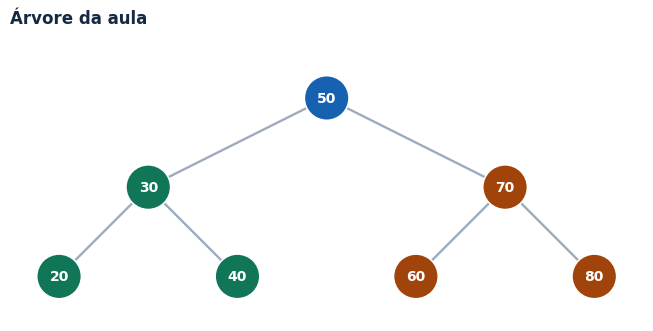

In [4]:
desenhar(raiz, "Árvore da aula", destaque={50: AZUL, 20: VERDE, 30: VERDE, 40: VERDE,
                                           60: LARANJA, 70: LARANJA, 80: LARANJA})
plt.show()

Na raiz `50`, os nós verdes são menores que `50` e os laranja são maiores. Observe também o nó `70`. Sua subárvore esquerda contém `60`, e sua subárvore direita contém `80`.

O exemplo a seguir mostra por que olhar apenas para o pai é insuficiente. Se trocarmos `40` por `55`, então `55 > 30`, mas `55` ficará no ramo esquerdo de `50`. Para validar a ABB, propagamos os limites de todos os ancestrais.

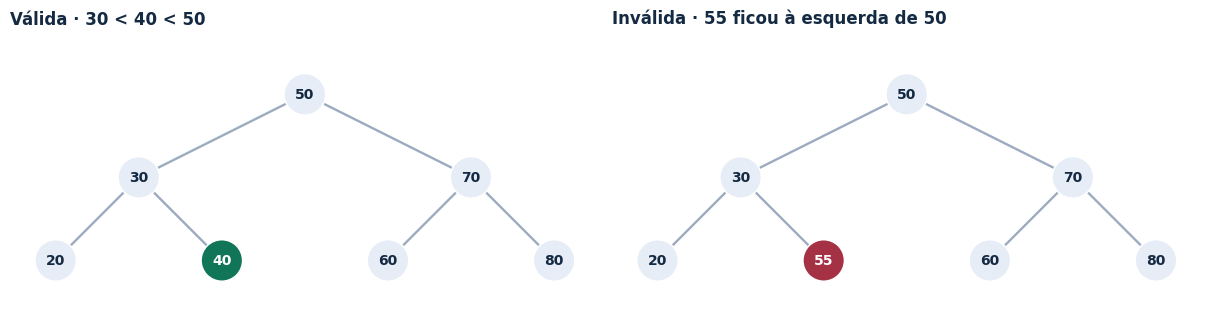

Árvore original é ABB? True
Árvore modificada é ABB? False


In [5]:
def eh_abb(no, menor=None, maior=None):
    if no is None:
        return True
    if menor is not None and no.chave <= menor:
        return False
    if maior is not None and no.chave >= maior:
        return False
    return (eh_abb(no.esq, menor, no.chave)
            and eh_abb(no.dir, no.chave, maior))

invalida = construir(CHAVES_BASE)
invalida.esq.dir.chave = 55
fig, (esquerda, direita) = painel()
desenhar(raiz, "Válida · 30 < 40 < 50", ax=esquerda, destaque={40: VERDE})
desenhar(invalida, "Inválida · 55 ficou à esquerda de 50", ax=direita, destaque={55: VERMELHO})
plt.show()
print(f"Árvore original é ABB? {eh_abb(raiz)}")
print(f"Árvore modificada é ABB? {eh_abb(invalida)}")

## 2. Percorrer todos os nós ou buscar uma chave?

Um **percurso completo** visita todos os nós. O ponto em que registramos a chave do nó atual define a ordem:

| Percurso | Sequência em cada subárvore |
|---|---|
| Pré-ordem | Nó atual, esquerda, direita |
| Em ordem | Esquerda, nó atual, direita |
| Pós-ordem | Esquerda, direita, nó atual |

Em uma ABB, o **percurso em ordem** lista as chaves em ordem crescente. Para **buscar uma chave**, começamos na raiz e, a cada comparação, escolhemos um único filho. Quando chegamos à chave, a busca termina. Se chegarmos a `None`, ela está ausente.

In [6]:
def em_ordem(no):
    saida = []

    def visitar(atual):
        if atual is None:
            return
        visitar(atual.esq)
        saida.append(atual.chave)
        visitar(atual.dir)

    visitar(no)
    return saida

def buscar_com_caminho(no, chave):
    caminho = []
    while no is not None:
        caminho.append(no.chave)
        if chave == no.chave:
            return no, caminho
        if chave < no.chave:
            no = no.esq
        else:
            no = no.dir
    return None, caminho

Os números pequenos indicam a ordem em que cada chave foi registrada. À esquerda, aparece a listagem completa. À direita, aparecem apenas os nós comparados na busca. Troque `chave_procurada` por `65` para ver o caminho de uma busca que termina em um filho vazio.

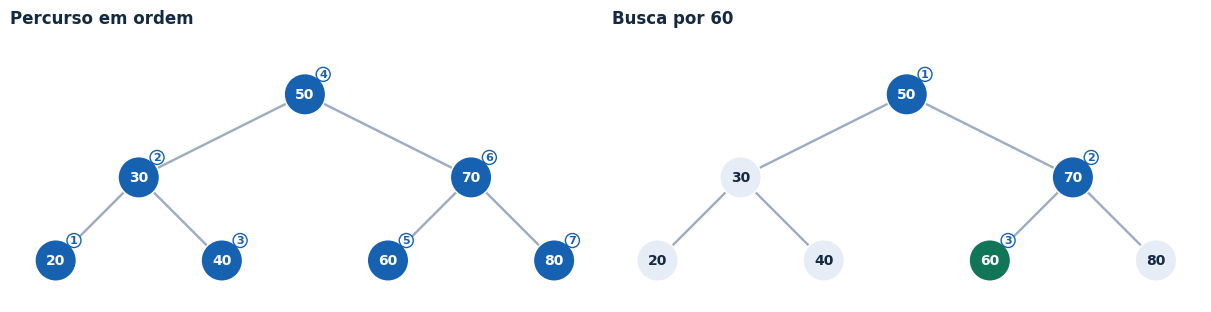

Chaves registradas em ordem: [20, 30, 40, 50, 60, 70, 80]
Nós comparados na busca: [50, 70, 60]
Resultado: 60


In [7]:
chave_procurada = 60
lista = em_ordem(raiz)
encontrado, caminho = buscar_com_caminho(raiz, chave_procurada)

fig, (esquerda, direita) = painel()
desenhar(raiz, "Percurso em ordem", ax=esquerda, visitados=lista, numerar=True)
destaque = {encontrado.chave: VERDE} if encontrado is not None else {}
desenhar(raiz, f"Busca por {chave_procurada}", ax=direita, visitados=caminho,
         destaque=destaque, numerar=True)
plt.show()

print("Chaves registradas em ordem:", lista)
print("Nós comparados na busca:", caminho)
print("Resultado:", encontrado.chave if encontrado is not None else "chave ausente")

## 3. Onde entra uma nova chave?

Para inserir `65`, comparamos com `50`, `70` e `60`, nessa sequência. Como `65 > 60`, seguimos à direita de `60`. A referência está vazia, então esse é o lugar do novo nó.

Depois da inserção, podemos executar **outra operação**, o percurso em ordem. Na lista que ele produz, `65` aparece entre `60` e `70`. A lista mostra a ordem das chaves, enquanto o caminho mostra onde o algoritmo fez as comparações.

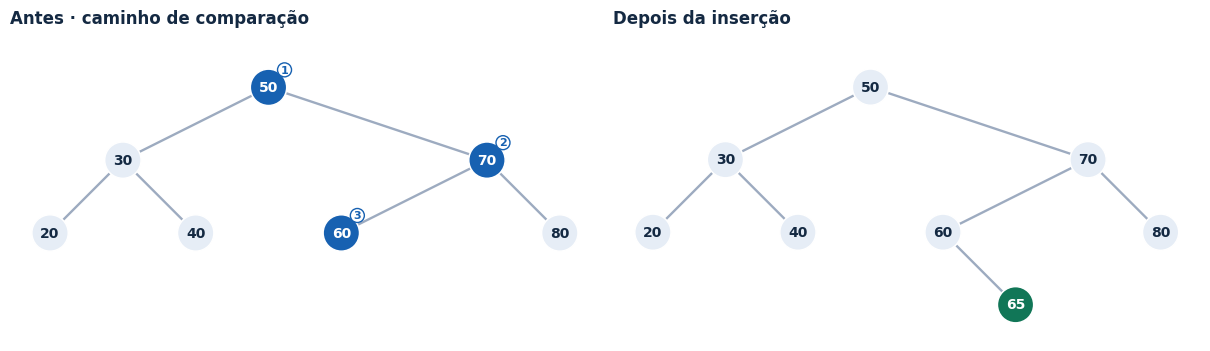

Caminho de comparação: [50, 70, 60]
Em ordem após inserir: [20, 30, 40, 50, 60, 65, 70, 80]


In [8]:
nova_chave = 65
antes = construir(CHAVES_BASE)
depois = construir(CHAVES_BASE)
existente, caminho = buscar_com_caminho(antes, nova_chave)
depois = inserir(depois, nova_chave)
posicoes = sorted(set(CHAVES_BASE + [nova_chave]))

fig, (esquerda, direita) = painel()
desenhar(antes, "Antes · caminho de comparação", ax=esquerda, chaves=posicoes,
         visitados=caminho, numerar=True)
desenhar(depois, "Depois da inserção", ax=direita, chaves=posicoes,
         destaque={nova_chave: VERDE})
plt.show()

print("Caminho de comparação:", caminho)
print("Em ordem após inserir:", em_ordem(depois))
if existente is not None:
    print("A chave já estava presente. A árvore conserva as mesmas ligações.")

## 4. O que muda quando removemos um nó?

Primeiro localizamos a chave pelas comparações da busca. Depois, o número de filhos determina como ligar a subárvore ao restante da árvore.

| Filhos do nó removido | O que a remoção devolve para ocupar sua posição |
|---|---|
| Nenhum | `None` |
| Um | O único filho, junto com sua subárvore |
| Dois | O nó com a chave do seu sucessor, após retirar a ocorrência antiga dessa chave |

Aqui, o **sucessor** é a menor chave da subárvore direita. Para encontrá-lo, entre pela direita e siga os filhos esquerdos enquanto eles existirem. Como é a menor chave desse ramo, o sucessor pode ter um filho direito. O código preserva esse filho ao remover a ocorrência antiga.

In [9]:
def minimo(no):
    while no.esq is not None:
        no = no.esq
    return no

def remover(no, chave):
    if no is None:
        return None
    if chave < no.chave:
        no.esq = remover(no.esq, chave)
        return no
    if chave > no.chave:
        no.dir = remover(no.dir, chave)
        return no
    if no.esq is None:
        return no.dir
    if no.dir is None:
        return no.esq

    sucessor = minimo(no.dir)
    no.chave = sucessor.chave
    no.dir = remover(no.dir, no.chave)
    return no

In [10]:
def comparar_remocao(chaves, chave, titulo, destaque_depois=None):
    antes = construir(chaves)
    encontrado, caminho = buscar_com_caminho(antes, chave)
    depois = remover(construir(chaves), chave)
    fig, (esquerda, direita) = painel(altura=4)
    destaque_antes = {chave: VERMELHO} if encontrado is not None else {}
    posicoes = sorted(set(chaves))
    desenhar(antes, titulo, ax=esquerda, chaves=posicoes,
             visitados=caminho, destaque=destaque_antes, numerar=True)
    desenhar(depois, "Depois da remoção", ax=direita, chaves=posicoes,
             destaque=destaque_depois)
    plt.show()
    print("Caminho até localizar a chave:", caminho)
    print("Em ordem após remover:", em_ordem(depois))
    print("A propriedade da ABB foi preservada?", eh_abb(depois))

### Caso A · folha

O nó `20` é uma folha. Quando ele sai, a referência esquerda de `30` passa a ser `None`.

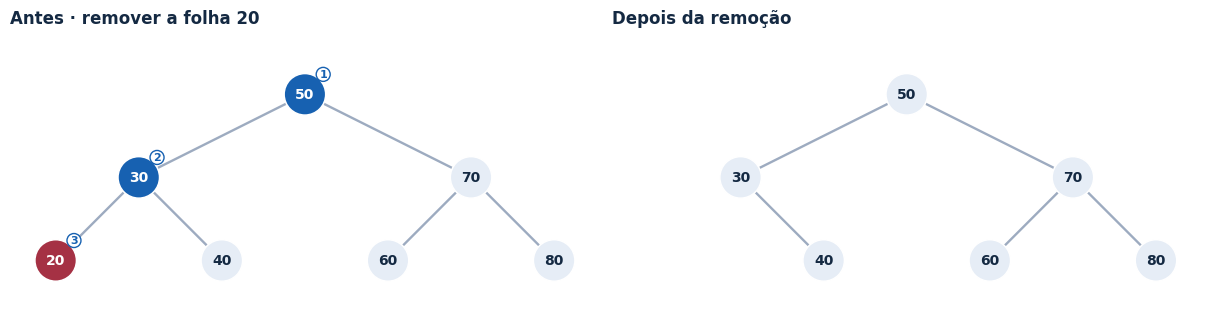

Caminho até localizar a chave: [50, 30, 20]
Em ordem após remover: [30, 40, 50, 60, 70, 80]
A propriedade da ABB foi preservada? True


In [11]:
comparar_remocao(CHAVES_BASE, 20, "Antes · remover a folha 20")

### Caso B · um filho

Acrescente `65` à árvore. Agora `60` tem um único filho, `65`. Ao remover `60`, a referência esquerda de `70` passa a apontar diretamente para `65`.

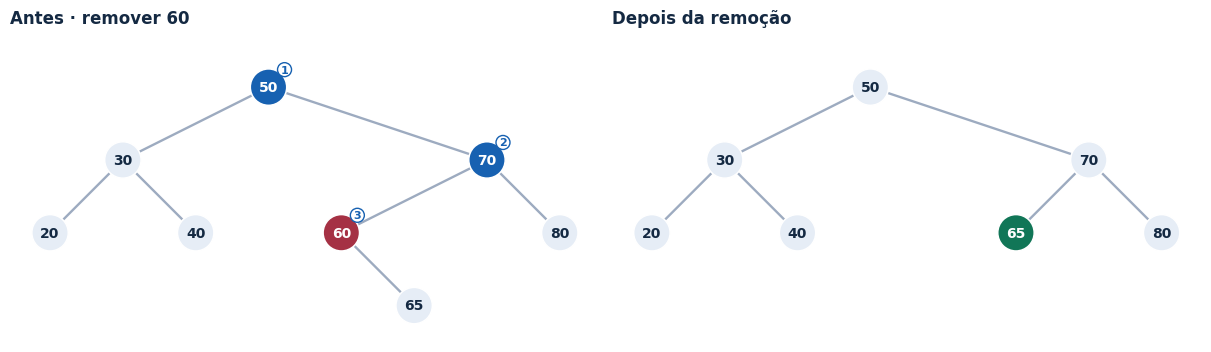

Caminho até localizar a chave: [50, 70, 60]
Em ordem após remover: [20, 30, 40, 50, 65, 70, 80]
A propriedade da ABB foi preservada? True


In [12]:
comparar_remocao(CHAVES_BASE + [65], 60, "Antes · remover 60",
                 destaque_depois={65: VERDE})

### Caso C · dois filhos

Na árvore ampliada com `55` e `57`, queremos remover `50`.

1. A subárvore direita começa em `70`. Seu menor elemento é `55`, encontrado pelo caminho `70 → 60 → 55`.
2. A raiz passa a guardar `55`.
3. A ocorrência antiga de `55` é removida. Seu filho direito, `57`, assume a posição que ficou livre como filho esquerdo de `60`.

Sucessor de 50: 55


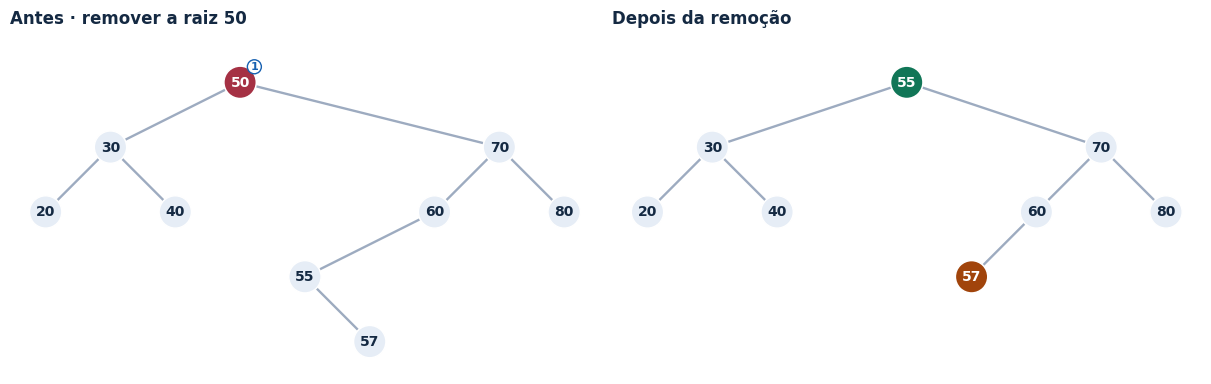

Caminho até localizar a chave: [50]
Em ordem após remover: [20, 30, 40, 55, 57, 60, 70, 80]
A propriedade da ABB foi preservada? True


In [13]:
chaves_ampliadas = CHAVES_BASE + [55, 57]
raiz_ampliada = construir(chaves_ampliadas)
print("Sucessor de 50:", minimo(raiz_ampliada.dir).chave)
comparar_remocao(chaves_ampliadas, 50, "Antes · remover a raiz 50",
                 destaque_depois={55: VERDE, 57: LARANJA})

## 5. Por que a altura importa?

A ordem de inserção muda a forma da ABB. Vamos inserir as **mesmas chaves** em duas ordens e buscar `80`. Na árvore da aula, a busca visita 3 nós. Na árvore construída com inserções crescentes, a busca visita 7.

Se a altura é `h` arestas, um caminho da raiz até um nó tem no máximo `h + 1` nós. Busca, inserção e remoção têm custo de pior caso proporcional a essa altura, enquanto uma listagem completa visita todos os `n` nós. Uma ABB com altura logarítmica permite operações em `O(log n)`. Em uma ABB em cadeia, elas podem custar `O(n)`.

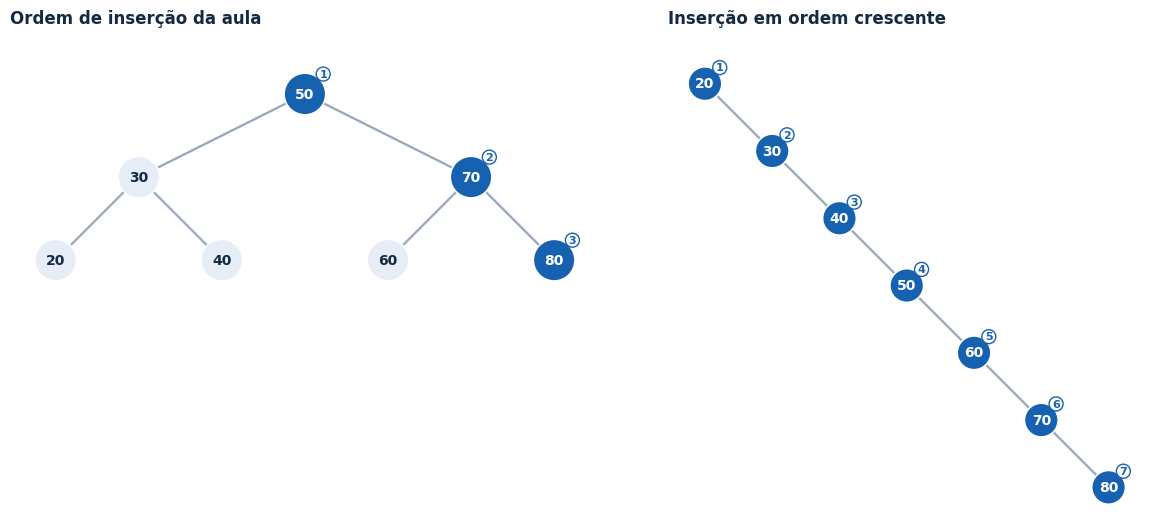

Árvore da aula: 2 arestas | 3 nós comparados
Árvore em cadeia: 6 arestas | 7 nós comparados


In [14]:
def altura(no):
    if no is None:
        return -1
    return 1 + max(altura(no.esq), altura(no.dir))

chave_medida = 80
arvore_aula = construir(CHAVES_BASE)
arvore_crescente = construir(sorted(CHAVES_BASE))
_, caminho_aula = buscar_com_caminho(arvore_aula, chave_medida)
_, caminho_crescente = buscar_com_caminho(arvore_crescente, chave_medida)

fig, (esquerda, direita) = painel(altura=5.2)
desenhar(arvore_aula, "Ordem de inserção da aula", ax=esquerda, visitados=caminho_aula,
         numerar=True)
desenhar(arvore_crescente, "Inserção em ordem crescente", ax=direita, visitados=caminho_crescente,
         numerar=True)
plt.show()
print("Árvore da aula:", altura(arvore_aula), "arestas |", len(caminho_aula), "nós comparados")
print("Árvore em cadeia:", altura(arvore_crescente), "arestas |", len(caminho_crescente), "nós comparados")

---
# 6. Questão — O laboratório precisa organizar seus equipamentos

**Missão prática · 1 hora e 30 minutos · Estruturas de Dados I · FACOMP/UFPA**

**Integrante(s):**
GUSTAVO LARA DA SILVA
CRISTIANO BATISTA SEABRA E SILVA
JOAO VICTOR DE ARAUJO NEVES

**Data:** 15/11/2026.

Vocês são a equipe responsável por transformar a fala de uma cliente em um pequeno protótipo. Será necessário **identificar os requisitos, justificar uma estrutura, completar quatro funções em Python e comprovar as conclusões pela execução**.

Se estiverem em dupla, alternem quem programa e quem confere a execução a cada etapa. Cada integrante deve conseguir explicar as decisões tomadas.

## A primeira reunião com a cliente

> “Cada equipamento tem uma etiqueta com um número único. Quando alguém me pergunta se o equipamento 35 está cadastrado, eu preciso procurar o número na minha lista. Hoje confiro um por um. Quero conseguir localizar um equipamento pelo número sem precisar olhar todos os outros.
>
> Toda sexta-feira, também preciso entregar um inventário com os números das etiquetas em ordem crescente. E o cadastro muda durante o semestre. Às vezes chega um equipamento novo, às vezes um equipamento é transferido para outro laboratório e precisa sair da nossa lista.
>
> Para vocês testarem, anotei os números dos equipamentos na ordem em que foram cadastrados: **40, 20, 60, 10, 30, 50, 70 e 35**. Nessa mesma semana, chegou um equipamento com a etiqueta **25** e o equipamento **20** foi transferido.”

**Resultado esperado do projeto:** um cadastro que responda às consultas, aceite a nova etiqueta, retire a etiqueta transferida e produza o inventário solicitado. Vocês deverão construir a árvore a partir dos dados; o desenho do cadastro inicial não está pronto.

## Organização dos 90 minutos

| Etapa | Tempo | O que vocês devem produzir |
|---|---:|---|
| 1. Ouvir e projetar | 10 min | Requisitos e justificativa da estrutura |
| 2. Construir e inspecionar | 15 min | Inserção, desenho e características da árvore |
| 3. Atender às consultas | 15 min | Busca com caminho e comparação com a lista |
| 4. Registrar a chegada | 10 min | Inserção do 25 e teste de etiqueta repetida |
| 5. Registrar a transferência | 20 min | Remoção e verificação dos três casos |
| 6. Entregar o inventário | 10 min | Percurso em ordem implementado pela equipe |
| 7. Avaliar e explicar | 10 min | Medidas de altura, conclusão e resposta à cliente |
| **Total** | **90 min** | **Notebook executado e respostas fundamentadas** |

### Como trabalhar e entregar

1. Execute as células anteriores do notebook para carregar a classe `No`, os desenhos e as funções de apoio. No Colab, use **Shift + Enter** para executar uma célula.
2. Primeiro registrem a previsão; depois executem e comparem. Uma resposta experimental deve citar uma saída, um caminho ou uma mudança observada no desenho.
3. Nas quatro funções `lab_inserir`, `lab_buscar`, `lab_remover` e `lab_inventario`, substituam cada linha `raise NotImplementedError(...)` pelo código pedido no comentário `TODO`. Esses avisos são lacunas intencionais. Não basta apagá-los sem implementar a operação.
4. Consultem os exemplos da aula, mas escrevam e expliquem a solução. Não substituam a implementação por chamadas às versões prontas `inserir`, `buscar_com_caminho`, `remover` ou `em_ordem`. A função `minimo` e os apoios de visualização e validação podem ser reutilizados.
5. Executem cada célula de teste depois de completar sua função. `PENDENTE` indica código a completar; `REVER` indica um resultado incompatível com a verificação. Um erro de Python com rastreamento deve ser investigado.
6. Preencham as células **Respostas** com os resultados reais. Ao terminar, executem novamente a atividade de cima para baixo e entreguem o `.ipynb` com os códigos, saídas e respostas. Se necessário, no Colab: **Arquivo → Fazer download → Fazer download do .ipynb**.

Os experimentos reconstroem seus próprios cadastros para que uma nova execução não acumule inserções ou remoções de uma tentativa anterior. O protótipo armazena somente etiquetas inteiras distintas; os demais dados do equipamento serão discutidos na modelagem.

## Etapa 1 · Ouvir o problema e projetar a solução · 10 min

A cliente descreveu necessidades do trabalho, sem indicar qual estrutura programar. Antes de abrir o código, transformem a fala em operações.

**P1.** Preencham a tabela de requisitos. Depois indiquem a informação que identifica um equipamento de forma única e dois outros campos úteis para um cadastro real.

**P2.** Entre lista, pilha, fila e árvore, qual estrutura vocês propõem para este cadastro? Se escolherem uma árvore, indiquem o tipo e a regra de organização. Relacionem a proposta a **duas necessidades da cliente** e expliquem por que pilha ou fila, sozinhas, não atendem bem a essas necessidades. Outras propostas justificadas podem ser discutidas com a professora.

### Respostas · Etapa 1

| Trecho da fala da cliente | Operação que o sistema precisa oferecer |
|---|---|
| “O equipamento 35 está cadastrado?” | Busca (pesquisa de chave) |
| “Chegou um equipamento com a etiqueta 25.” | Inserção |
| “O equipamento 20 foi transferido.” | Remoção |
| “Inventário com os números em ordem crescente.” | Percurso em-ordem (Travessia ordenada) |

**Identificador único e outros campos:**
O identificador único é o número da etiqueta do equipamento. Dois outros campos úteis seriam: "Nome/Tipo do equipamento" (ex: Osciloscópio, Computador) e "Estado de conservação" (ex: Ativo, Manutenção).

**Estrutura proposta, regra e justificativa:**
Árvore Binária de Busca. Ela permite localizar, inserir e remover equipamentos mantendo uma organização baseada nas etiquetas. Quando a árvore está equilibrada, essas operações têm custo O(logn). Em uma ABB comum, porém, o custo depende da altura h e é O(h); se a árvore ficar degenerada, pode chegar a O(n).


**Pilha e fila diante desse pedido:**
Uma pilha organiza os elementos pela regra LIFO (o último que entra é o primeiro que sai), e uma fila pela regra FIFO (o primeiro que entra é o primeiro que sai). Essas estruturas priorizam a ordem de chegada, não a busca ordenada por etiqueta. Por isso, a ABB é mais adequada às necessidades do cadastro.

In [15]:
# Apoio pronto: execute sem modificar. Os nomes lab_ isolam a atividade dos exemplos.
ORDEM_CADASTRO = [40, 20, 60, 10, 30, 50, 70, 35]

def lab_conferir(titulo, experimento):
    try:
        experimento()
    except NotImplementedError as erro:
        print(f"PENDENTE — {titulo}: {erro}")
    except AssertionError as erro:
        print(f"REVER — {titulo}: {erro}")
    else:
        print(f"CONFERIDO — {titulo}")

def lab_chaves(no):
    # Inspeção pronta para os testes. Não use dentro de lab_inventario.
    return [atual.chave for atual in nos_em_ordem(no)]

def lab_montar(chaves):
    raiz_lab = None
    for etiqueta in chaves:
        raiz_lab = lab_inserir(raiz_lab, etiqueta)
    return raiz_lab

def lab_ligacoes(no):
    # Retrato das chaves e dos ramos, para detectar mudanças indevidas.
    if no is None:
        return None
    return (no.chave, lab_ligacoes(no.esq), lab_ligacoes(no.dir))

def lab_inspecionar(no):
    print("Raiz:", None if no is None else no.chave)
    print("Folhas:", [n.chave for n in nos_em_ordem(no)
                      if n.esq is None and n.dir is None])
    print("Subárvore esquerda da raiz:", [] if no is None else lab_chaves(no.esq))
    print("Subárvore direita da raiz:", [] if no is None else lab_chaves(no.dir))
    print("Total de nós:", len(lab_chaves(no)))
    print("Altura em arestas:", altura(no))
    print("Respeita os limites de uma ABB?", eh_abb(no))

print("Apoios carregados. A primeira função a completar é lab_inserir.")

Apoios carregados. A primeira função a completar é lab_inserir.


## Etapa 2 · Construir e inspecionar o cadastro inicial · 15 min

**Antes de executar:** esbocem a árvore no caderno, inserindo as etiquetas **na ordem informada pela cliente**. Prevejam qual será a raiz e onde o 35 ficará. Não ordenem os dados antes de inserir.

Completem `lab_inserir`. Ela recebe a raiz de uma subárvore e uma etiqueta, e devolve a raiz dessa subárvore após a operação. A estrutura recursiva já está indicada; faltam a criação do nó e as ligações com os filhos.

**Pista:** para inserir em uma árvore vazia, criem um `No`. Para uma chave menor ou maior, o retorno da chamada recursiva deve atualizar o filho adequado. Uma etiqueta igual deve conservar o cadastro sem criar duplicata.

In [16]:
def lab_inserir(no, etiqueta):
    if no is None:
        return No(etiqueta)
    if etiqueta < no.chave:
        no.esq = lab_inserir(no.esq, etiqueta)
    elif etiqueta > no.chave:
        no.dir = lab_inserir(no.dir, etiqueta)
    return no

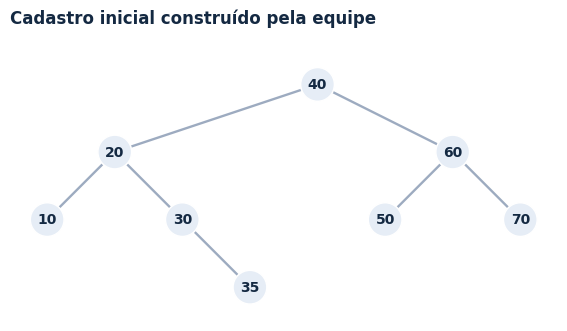

Raiz: 40
Folhas: [10, 35, 50, 70]
Subárvore esquerda da raiz: [10, 20, 30, 35]
Subárvore direita da raiz: [50, 60, 70]
Total de nós: 8
Altura em arestas: 3
Respeita os limites de uma ABB? True
CONFERIDO — construção do cadastro inicial


In [17]:
def lab_experimento_inicial():
    cadastro = lab_montar(ORDEM_CADASTRO)
    desenhar(cadastro, "Cadastro inicial construído pela equipe")
    plt.show()
    lab_inspecionar(cadastro)
    assert eh_abb(cadastro), "Verifique a direção das comparações e as ligações."
    assert set(lab_chaves(cadastro)) == set(ORDEM_CADASTRO), "Alguma etiqueta se perdeu."
    assert len(lab_chaves(cadastro)) == len(ORDEM_CADASTRO), "Há nós a mais ou a menos."

lab_conferir("construção do cadastro inicial", lab_experimento_inicial)

**P3.** Comparem o esboço com o desenho gerado. Registrem raiz, folhas, subárvores e altura. Expliquem por quais comparações a etiqueta 35 chegou à posição observada. Por que esta estrutura é uma árvore binária? O que mais é necessário para classificá-la como uma ABB?

A raiz é 40 e as folhas são 10, 35, 50 e 70. A sub-árvore esquerda da raiz contém [10, 20, 30, 35], e a direita contém [50, 60, 70].
A altura é de 3 arestas. A etiqueta 35 chegou à posição observada pelas comparações:
35 < 40, então segue à esquerda.
35 > 20, então segue à direita.
35 > 30, então fica à direita de 30.
É uma árvore binária porque cada nó tem, no máximo, dois filhos.
Para ser uma ABB, além disso, todas as chaves da subárvore esquerda de cada nó devem ser menores que sua chave, e todas as da sub-árvore direita devem ser maiores, respeitando também os limites dos ancestrais.

### Um cadastro aparentemente correto pode ter um erro

Na próxima célula, uma cópia do cadastro sofre uma alteração proposital: o nó que era 35 passa a armazenar 45, sem mudar de lugar. **Prevejam** o resultado de `eh_abb` antes de executar. A cópia com erro não será usada nos pedidos da cliente.

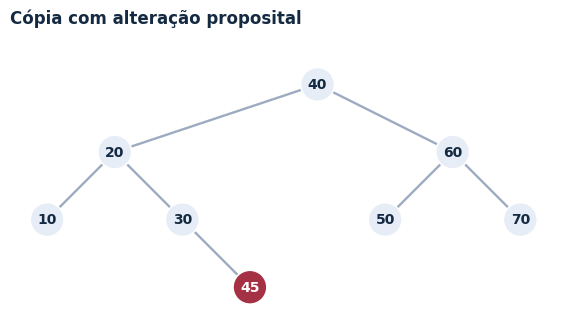

45 é maior que seu pai? True
45 pertence à subárvore esquerda da raiz? Sim, pelas ligações.
Essa cópia é uma ABB? False
CONFERIDO — investigação dos limites


In [18]:
def lab_experimento_limites():
    copia_com_erro = lab_montar(ORDEM_CADASTRO)
    copia_com_erro.esq.dir.dir.chave = 45
    desenhar(copia_com_erro, "Cópia com alteração proposital", destaque={45: VERMELHO})
    plt.show()
    print("45 é maior que seu pai?", 45 > copia_com_erro.esq.dir.chave)
    print("45 pertence à subárvore esquerda da raiz? Sim, pelas ligações.")
    print("Essa cópia é uma ABB?", eh_abb(copia_com_erro))

lab_conferir("investigação dos limites", lab_experimento_limites)

### Respostas · Etapa 2

**P3 — Previsão do desenho e posição do 35:** Antes de executar, prevemos que a raiz será o primeiro elemento inserido (40). O 35 será inserido seguindo as regras da ABB: comparado com 40 (vai para a esquerda), depois com 20 (vai para a direita), depois com 30 (vai para a direita), ficando como filho direito do nó 30.

| Característica | Resultado observado |
|---|---|
| Raiz | 40 |
| Folhas | [10, 35, 50, 70] |
| Chaves da subárvore esquerda da raiz | [10, 20, 30, 35] |
| Chaves da subárvore direita da raiz | [50, 60, 70] |
| Altura em arestas | 3 |

**Comparações para inserir o 35; árvore binária e propriedade da ABB:**
As comparações executadas para inserir o o 35 foram:
35 < 40 (esquerda), 35 > 20 (direita) e 35 > 30 (direita). Como a posição de filho direito de 30 estava vazia (`None`), o novo nó foi criado ali.
Esta estrutura é uma **árvore binária** porque cada nó possui no máximo dois filhos (esquerdo e direito). Para ser classificada como uma **ABB (Árvore Binária de Busca)**, ela precisa obedecer à regra de que todos os nós da subárvore esquerda de qualquer nó possuem chaves estritamente menores que a dele, e todos da subárvore direita possuem chaves estritamente maiores.

**P4 — Cópia com erro:** A previsão era que `eh_abb(copia_com_erro)` retornaria `False`, o que se confirmou na execução. O nó 45 passou a violar o limite do ancestral raiz (40), uma vez que 45 > 40 e ele se localiza na subárvore esquerda de 40. Verificar apenas a relação com o pai (45 > 30) não basta, pois um nó pode respeitar a relação local com seu pai imediato e ainda assim violar as restrições impostas pelos ancestrais mais distantes da árvore.

## Etapa 3 · Atender às consultas da cliente · 15 min

> “O equipamento 35 está cadastrado? E o equipamento 99?”

Completem `lab_buscar`. Ela deve devolver **dois resultados**: o nó encontrado (ou `None`) e a lista das etiquetas consultadas, na ordem. A cada passo, escolham somente um ramo.

**Antes de executar:** prevejam o caminho de cada consulta. O caminho deve conter apenas chaves de nós existentes; não incluam `None`.

**Pista:** a igualdade encerra a busca. Se a etiqueta for menor, atualizem a referência para o filho esquerdo; caso contrário, para o direito. Se a referência acabar, o item está ausente.

Se a célula não terminar, interrompam a execução e confiram se `no` está sendo atualizado dentro do laço.

In [21]:
def lab_buscar(no, etiqueta):
    caminho = []
    while no is not None:
        caminho.append(no.chave)
        if etiqueta == no.chave:
            return no, caminho
        if etiqueta < no.chave:
            no = no.esq
        else:
            no = no.dir
    return None, caminho


Etiqueta 35
Localizada na ABB? True
Caminho na ABB: [40, 20, 30, 35] | nós consultados: 4
Caminho na lista: [40, 20, 60, 10, 30, 50, 70, 35] | itens consultados: 8

Etiqueta 99
Localizada na ABB? False
Caminho na ABB: [40, 60, 70] | nós consultados: 3
Caminho na lista: [40, 20, 60, 10, 30, 50, 70, 35] | itens consultados: 8


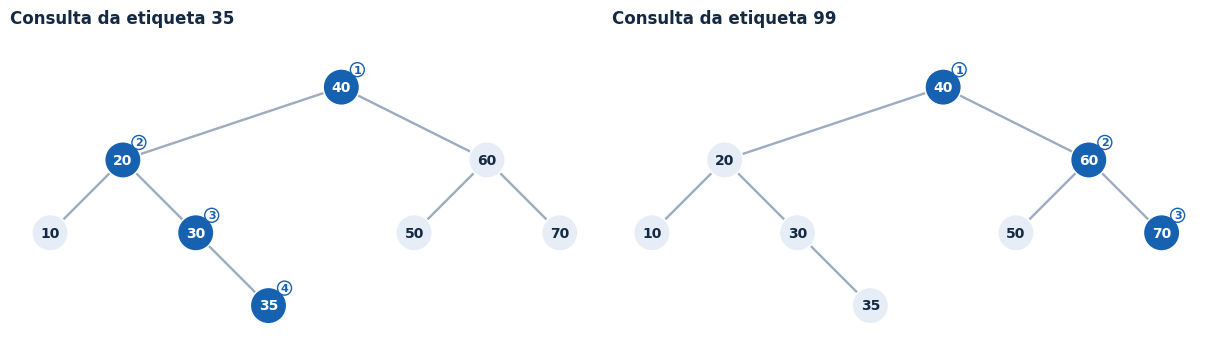

CONFERIDO — consultas com caminho


In [22]:
# Comparação pronta com a lista da cliente, na ordem original.
def lab_busca_na_lista(etiquetas, procurada):
    consultadas = []
    for etiqueta in etiquetas:
        consultadas.append(etiqueta)
        if etiqueta == procurada:
            return True, consultadas
    return False, consultadas

def lab_experimento_busca():
    cadastro = lab_montar(ORDEM_CADASTRO)
    fig, eixos = painel(altura=4.2)
    for procurada, eixo in zip((35, 99), eixos):
        no, caminho = lab_buscar(cadastro, procurada)
        presente_lista, caminho_lista = lab_busca_na_lista(ORDEM_CADASTRO, procurada)
        desenhar(cadastro, f"Consulta da etiqueta {procurada}", ax=eixo,
                 visitados=caminho, numerar=True)
        print(f"\nEtiqueta {procurada}")
        print("Localizada na ABB?", no is not None)
        print("Caminho na ABB:", caminho, "| nós consultados:", len(caminho))
        print("Caminho na lista:", caminho_lista, "| itens consultados:", len(caminho_lista))
        assert (no is not None) == presente_lista, "A busca divergiu da presença na lista."
        assert no is None or no.chave == procurada, "O nó retornado não é o procurado."
        assert caminho and caminho[0] == cadastro.chave, "A busca deve começar na raiz."
    plt.show()

lab_conferir("consultas com caminho", lab_experimento_busca)

### Respostas · Etapa 3

**P5 e P6.** Preenchido com as saídas obtidas do experimento de buscas:

| Etiqueta | Caminho previsto na ABB | Caminho observado na ABB | Encontrada? | Nós na ABB | Itens na lista |
|---|---|---|---|---:|---:|
| 35 | [40, 20, 30, 35] | [40, 20, 30, 35] | Sim | 4 | 8 |
| 99 | [40, 60, 70] | [40, 60, 70] | Não | 3 | 8 |

**P5 — Decisões:** Na busca pelo 35: começamos na raiz (40); como 35 < 40, tomamos a esquerda para o nó 20; como 35 > 20, tomamos a direita para o nó 30; como 35 > 30, tomamos a direita chegando ao nó 35 (encontrado). Na consulta por 99: começamos na raiz (40); como 99 > 40, vamos para a direita (60); como 99 > 60, vamos para a direita (70); como 99 > 70, tentaríamos ir para a direita, mas o filho direito de 70 é `None`, encerrando a busca e concluindo que o item está ausente.

**P6 — Comparação:** Para a etiqueta 35, apenas 4 nós foram consultados na ABB, enquanto na lista linear teríamos que percorrer todos os 8 itens (o 35 era o último cadastrado). A propriedade da ABB que permite isso é a ordenação estrita das subárvores, o que nos possibilita descartar metade dos caminhos a cada passo. Esses testes **não** provam que qualquer ABB será rápida para qualquer entrada, pois se a árvore estiver desbalanceada (em cadeia/degenerada), ela se comportará exatamente como uma lista linear, necessitando de buscas $O(n)$.

## Etapa 4 · Registrar a chegada de um equipamento · 10 min

> “Cadastrem o equipamento 25. Se eu enviar essa mesma etiqueta duas vezes, não criem dois equipamentos.”

Usem a inserção que vocês implementaram. O teste abaixo busca o 25 **antes** de inserir: esse caminho mostra os nós usados para encontrar o ramo livre. Depois ele insere a etiqueta e tenta repeti-la.

**Antes de executar:** anotem qual nó será o pai do 25 e de qual lado ele entrará. Observem a atribuição `cadastro = lab_inserir(cadastro, 25)` e pensem no que ocorreria se o cadastro estivesse vazio.

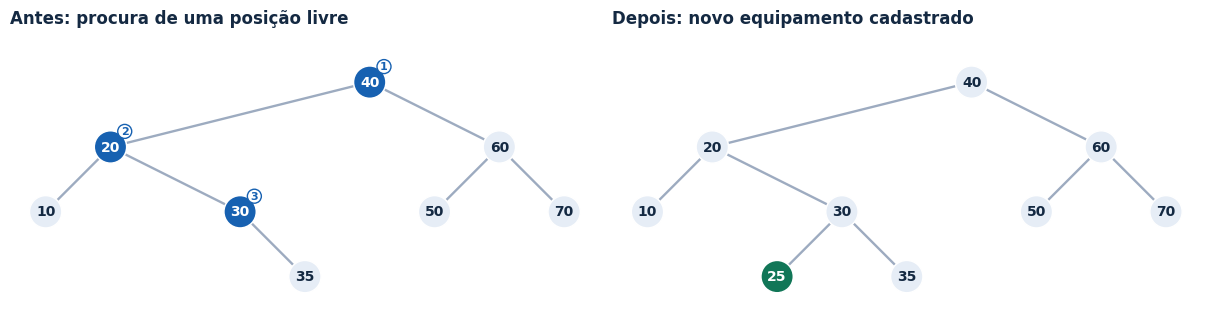

O 25 existia antes? False
Nós consultados antes da inserção: [40, 20, 30]
Total após inserir e após repetir: 9 9
Ligações preservadas ao repetir? True
Continua sendo ABB? True
CONFERIDO — chegada e etiqueta repetida


In [23]:
def lab_experimento_chegada():
    antes = lab_montar(ORDEM_CADASTRO)
    encontrado, caminho = lab_buscar(antes, 25)
    cadastro = lab_montar(ORDEM_CADASTRO)
    cadastro = lab_inserir(cadastro, 25)
    retrato = lab_ligacoes(cadastro)
    quantidade_antes = len(lab_chaves(cadastro))
    cadastro = lab_inserir(cadastro, 25)
    quantidade_depois = len(lab_chaves(cadastro))

    fig, (esquerda, direita) = painel(altura=4.2)
    posicoes = sorted(set(ORDEM_CADASTRO + [25]))  # Apenas para alinhar os desenhos.
    desenhar(antes, "Antes: procura de uma posição livre", ax=esquerda,
             chaves=posicoes, visitados=caminho, numerar=True)
    desenhar(cadastro, "Depois: novo equipamento cadastrado", ax=direita,
             chaves=posicoes, destaque={25: VERDE})
    plt.show()
    print("O 25 existia antes?", encontrado is not None)
    print("Nós consultados antes da inserção:", caminho)
    print("Total após inserir e após repetir:", quantidade_antes, quantidade_depois)
    print("Ligações preservadas ao repetir?", retrato == lab_ligacoes(cadastro))
    print("Continua sendo ABB?", eh_abb(cadastro))
    assert eh_abb(cadastro), "A inserção violou a ordenação."
    assert set(lab_chaves(cadastro)) == set(ORDEM_CADASTRO + [25]), "Confira as etiquetas."
    assert quantidade_antes == len(set(ORDEM_CADASTRO + [25])), "Quantidade incorreta."
    assert quantidade_depois == quantidade_antes, "Uma etiqueta repetida criou outro nó."
    assert retrato == lab_ligacoes(cadastro), "A repetição modificou as ligações."

lab_conferir("chegada e etiqueta repetida", lab_experimento_chegada)

### Respostas · Etapa 4

**P7 — Previsão:** O nó pai do 25 será o nó 30. Ele entrará do lado esquerdo de 30, pois 25 < 30 (e 25 > 20).

**P7 — Evidências:**
- Caminho observado: [40, 20, 30]
- Pai observado: 30 | Lado observado: esquerdo
- Total de nós após a 1ª inserção: 9 | Total após a 2ª tentativa: 9
- Resultado da validação: True (Continua sendo ABB)

**Explicação:** O 25 respeita o limite da raiz (40) porque ele foi corretamente inserido na subárvore esquerda, onde todos os nós são menores que 40. É necessário guardar o retorno da chamada (`cadastro = lab_inserir(...)`) porque, se a árvore estivesse vazia (`None`), ela precisará retornar a referência para o primeiro nó criado que agora passará a ser a nova raiz.

## Etapa 5 · Registrar a transferência e preservar o cadastro · 20 min

> “O equipamento 20 foi transferido. Retirem somente ele: os demais precisam continuar cadastrados.”

O estado deste pedido é o cadastro inicial **com o 25 já inserido**. Completem `lab_remover`. A localização do nó está pronta; faltam os retornos dos casos simples e o tratamento de dois filhos.

| Situação do nó encontrado | O que a implementação deve fazer |
|---|---|
| Não tem filho esquerdo | Devolver o filho direito, inclusive quando ele for `None` |
| Tem filho esquerdo, mas não tem direito | Devolver o filho esquerdo |
| Tem dois filhos | Obter o mínimo do ramo direito, copiar sua chave e retirar a ocorrência antiga desse sucessor |

**Pistas para a implementação:**

- A função `minimo` da aula está pronta e devolve um **nó**. Vocês podem usá-la aqui.
- Depois de copiar a chave sucessora, uma chamada recursiva deve atualizar `no.dir`; ao final, devolvam `no`.
- Preservem os retornos em cada chamada. Quem chamou a remoção precisa religar a raiz que ela devolveu.

**Antes de executar:** quantos filhos tem o 20 nesse estado? Qual chave poderia assumir sua posição usando o sucessor em ordem? Registrem a previsão na resposta P8.

In [24]:
def lab_remover(no, etiqueta):
    if no is None:
        return None
    if etiqueta < no.chave:
        no.esq = lab_remover(no.esq, etiqueta)
        return no
    if etiqueta > no.chave:
        no.dir = lab_remover(no.dir, etiqueta)
        return no

    # A etiqueta foi encontrada. Agora decidimos como religar o ramo.
    if no.esq is None:
        return no.dir
    if no.dir is None:
        return no.esq

    sucessor = minimo(no.dir)
    no.chave = sucessor.chave
    no.dir = lab_remover(no.dir, no.chave)
    return no

Caminho até o equipamento transferido: [40, 20]
Quantidade de filhos do nó removido: 2
Sucessor escolhido: 25


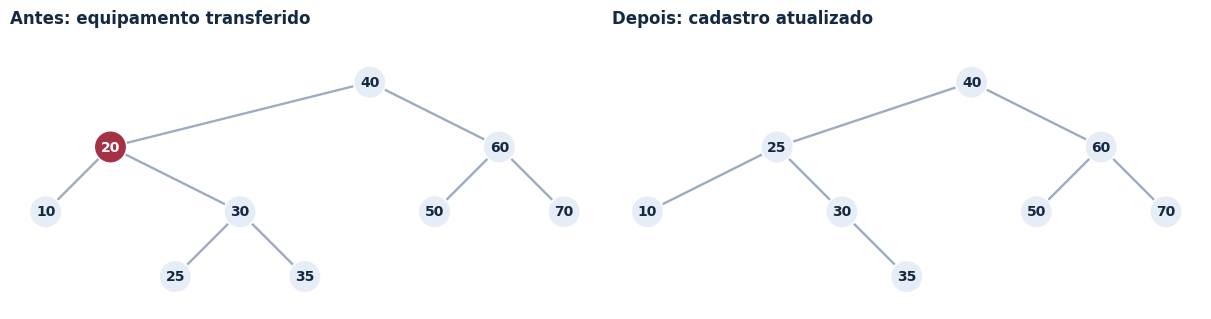

Total antes e depois: 9 8
Ocorrências da chave sucessora: 1
A propriedade da ABB foi preservada? True
CONFERIDO — transferência do equipamento 20


In [25]:
def lab_experimento_transferencia():
    dados_semana = ORDEM_CADASTRO + [25]
    antes = lab_montar(dados_semana)
    alvo, caminho = lab_buscar(antes, 20)
    assert alvo is not None, "O cadastro deveria conter o equipamento transferido."
    filhos = sum(filho is not None for filho in (alvo.esq, alvo.dir))
    print("Caminho até o equipamento transferido:", caminho)
    print("Quantidade de filhos do nó removido:", filhos)
    if filhos == 2:
        print("Sucessor escolhido:", minimo(alvo.dir).chave)

    depois = lab_remover(lab_montar(dados_semana), 20)
    fig, (esquerda, direita) = painel(altura=4.2)
    posicoes = sorted(set(dados_semana))
    desenhar(antes, "Antes: equipamento transferido", ax=esquerda,
             chaves=posicoes, destaque={20: VERMELHO})
    desenhar(depois, "Depois: cadastro atualizado", ax=direita, chaves=posicoes)
    plt.show()
    restante = lab_chaves(depois)
    print("Total antes e depois:", len(lab_chaves(antes)), len(restante))
    print("Ocorrências da chave sucessora:", restante.count(minimo(alvo.dir).chave))
    print("A propriedade da ABB foi preservada?", eh_abb(depois))
    no, _ = lab_buscar(depois, 20)
    assert no is None, "O equipamento transferido ainda é encontrado."
    assert eh_abb(depois), "A remoção violou os limites de algum ramo."
    assert set(restante) == set(dados_semana) - {20}, "Outra etiqueta se perdeu."
    assert len(restante) == len(set(dados_semana)) - 1, "Confira a retirada da cópia do sucessor."

lab_conferir("transferência do equipamento 20", lab_experimento_transferencia)

### Confiram os outros casos antes de entregar

Uma função do cadastro precisa funcionar para outras transferências. Os testes seguintes são **experimentos independentes**; não retiram mais etiquetas do cadastro da semana.

| Experimento | Estado reconstruído | Remoção testada |
|---|---|---:|
| A | Cadastro inicial, sem inserir 25 | 35 |
| B | Cadastro inicial, sem inserir 25 | 30 |
| C | Cadastro inicial com 25 | 20 |

Antes de executar, classifiquem cada nó em **folha, um filho ou dois filhos**. A saída mostra suas referências antes e depois da remoção. O programa também verifica raiz com um filho de cada lado, árvore unitária, chave ausente e árvore vazia.

In [26]:
def lab_testar_casos_remocao():
    for nome, dados, etiqueta in (
        ("A", ORDEM_CADASTRO, 35),
        ("B", ORDEM_CADASTRO, 30),
        ("C", ORDEM_CADASTRO + [25], 20),
    ):
        cadastro = lab_montar(dados)
        alvo, _ = lab_buscar(cadastro, etiqueta)
        filhos = sum(f is not None for f in (alvo.esq, alvo.dir))
        print(f"\nExperimento {nome}: retirar {etiqueta}; filhos antes = {filhos}")
        print("Antes (chave, esquerda, direita):", lab_ligacoes(cadastro))
        cadastro = lab_remover(cadastro, etiqueta)
        print("Depois (chave, esquerda, direita):", lab_ligacoes(cadastro))
        chaves = lab_chaves(cadastro)
        assert eh_abb(cadastro), f"O caso {nome} violou a ABB."
        assert set(chaves) == set(dados) - {etiqueta}, f"O caso {nome} perdeu dados."
        assert len(chaves) == len(set(dados)) - 1, f"O caso {nome} deixou uma duplicata."

    assert lab_remover(None, 20) is None, "A árvore vazia deve continuar vazia."
    unica = lab_remover(lab_montar([8]), 8)
    assert unica is None, "Ao retirar o único nó, a nova raiz deve ser None."
    for dados in ([8, 4], [8, 12]):
        nova_raiz = lab_remover(lab_montar(dados), 8)
        assert nova_raiz is not None and nova_raiz.chave == dados[1], "O único filho deve assumir a raiz."
        assert lab_chaves(nova_raiz) == dados[1:], "O ramo do único filho não foi preservado."
    cadastro = lab_montar(ORDEM_CADASTRO)
    retrato = lab_ligacoes(cadastro)
    cadastro = lab_remover(cadastro, 999)
    assert retrato == lab_ligacoes(cadastro), "Remover chave ausente alterou o cadastro."
    print("\nConferidos também: raiz com um filho de cada lado, árvore vazia, único nó e etiqueta ausente.")

lab_conferir("folha, um filho, dois filhos e limites", lab_testar_casos_remocao)


Experimento A: retirar 35; filhos antes = 0
Antes (chave, esquerda, direita): (40, (20, (10, None, None), (30, None, (35, None, None))), (60, (50, None, None), (70, None, None)))
Depois (chave, esquerda, direita): (40, (20, (10, None, None), (30, None, None)), (60, (50, None, None), (70, None, None)))

Experimento B: retirar 30; filhos antes = 1
Antes (chave, esquerda, direita): (40, (20, (10, None, None), (30, None, (35, None, None))), (60, (50, None, None), (70, None, None)))
Depois (chave, esquerda, direita): (40, (20, (10, None, None), (35, None, None)), (60, (50, None, None), (70, None, None)))

Experimento C: retirar 20; filhos antes = 2
Antes (chave, esquerda, direita): (40, (20, (10, None, None), (30, (25, None, None), (35, None, None))), (60, (50, None, None), (70, None, None)))
Depois (chave, esquerda, direita): (40, (25, (10, None, None), (30, None, (35, None, None))), (60, (50, None, None), (70, None, None)))

Conferidos também: raiz com um filho de cada lado, árvore vazia

### Respostas · Etapa 5

**P8 — Previsão para a remoção do 20 após inserir 25:** O nó 20 possui 2 filhos (10 na esquerda e 30 na direita). O sucessor em ordem previsto é o menor valor da subárvore direita de 20, que é o nó 25.

| Experimento | Nó removido | Tipo previsto | Filhos observados | Qual ligação mudou? |
|---|---:|---|---:|---|
| A | 35 | Folha | 0 | O filho direito de 30 passou a ser `None` |
| B | 30 | Um filho | 1 | O filho direito de 20 passou a apontar diretamente para 35 |
| C | 20 | Dois filhos | 2 | A chave de 20 foi substituída por 25, e o antigo nó contendo 25 foi removido |

**Explique o caso C:** A chave que ocupou o lugar de 20 foi a do seu sucessor em ordem, 25. A função copiou essa chave para o nó que guardava o 20 e removeu o nó original do 25, que era folha. Assim, após a remoção, restou apenas uma ocorrência do valor 25. O total de nós passou de 9 para 8.

**Justifique a preservação:** A validação com eh_abb retornou True, e o conjunto de chaves restantes corresponde ao conjunto original menos a etiqueta 20. Os testes também verificaram a remoção de uma etiqueta ausente, a árvore vazia, a remoção do único nó e raízes com um filho à esquerda ou à direita. No caso do único nó, a remoção da raiz devolve None; por isso, é necessário guardar o retorno com cadastro = lab_remover(...) para atualizar corretamente a raiz.

## Etapa 6 · Entregar o inventário de sexta-feira · 10 min

> “Agora me entreguem os números das etiquetas em ordem crescente.”

Desenvolvam o corpo recursivo de `lab_inventario`. Ela deve produzir uma lista usando **as ligações da árvore**. Não usem `sorted`, `sort`, `em_ordem`, `nos_em_ordem` ou `lab_chaves` dentro desta função; essas soluções esconderiam o percurso que vocês precisam implementar.

**Antes de executar:** escrevam o inventário previsto considerando os dois pedidos: inserir 25 e remover 20.

**Pista:** em cada subárvore, decidam em que momento registrar a chave atual para que as menores venham antes e as maiores depois. O ramo vazio encerra a chamada.

In [27]:
def lab_inventario(no):
    etiquetas = []

    def visitar(atual):
        if atual is None:
            return
        visitar(atual.esq)
        etiquetas.append(atual.chave)
        visitar(atual.dir)

    visitar(no)
    return etiquetas

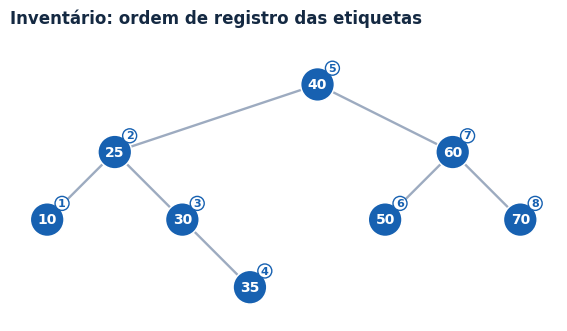

Inventário de sexta-feira: [10, 25, 30, 35, 40, 50, 60, 70]
Equipamentos listados: 8
Todos os valores aparecem em ordem estritamente crescente? True
CONFERIDO — inventário da semana


In [28]:
def lab_cadastro_da_semana():
    cadastro = lab_montar(ORDEM_CADASTRO)
    cadastro = lab_inserir(cadastro, 25)
    cadastro = lab_remover(cadastro, 20)
    return cadastro

def lab_experimento_inventario():
    cadastro = lab_cadastro_da_semana()
    inventario = lab_inventario(cadastro)
    desenhar(cadastro, "Inventário: ordem de registro das etiquetas",
             visitados=inventario, numerar=True)
    plt.show()
    print("Inventário de sexta-feira:", inventario)
    print("Equipamentos listados:", len(inventario))
    print("Todos os valores aparecem em ordem estritamente crescente?",
          all(a < b for a, b in zip(inventario, inventario[1:])))
    esperadas = (set(ORDEM_CADASTRO) | {25}) - {20}
    # Aqui sorted serve apenas de referência de teste; o inventário veio da sua função.
    assert inventario == sorted(esperadas), "Confira a ordem das três ações e os dados da semana."
    assert lab_inventario(None) == [], "O inventário de uma árvore vazia deve ser uma lista vazia."

lab_conferir("inventário da semana", lab_experimento_inventario)

### Respostas · Etapa 6

**P9 — Inventário previsto:** [10, 25, 30, 35, 40, 50, 60, 70]

**Inventário observado e quantidade de equipamentos:** [10, 25, 30, 35, 40, 50, 60, 70] | Quantidade: 8 equipamentos.

**Percurso e recursão:** Implementamos o percurso **Em-ordem (In-order)**. Ele atende ao pedido porque visita primeiro a subárvore esquerda (valores menores), depois o nó atual (raiz local) e, por fim, a subárvore direita (valores maiores). No desenho final, quando a chamada retorna do ramo esquerdo da raiz, a própria chave da raiz `40` será registrada em seguida. A estrutura usada pelo Python para gerenciar o ponto de retorno das chamadas recursivas é a **Pilha de Execução (Call Stack)**.

**Busca versus inventário:** A busca segue um único ramo a cada comparação, pois a chave buscada é menor ou maior que a do nó atual. Esse caminho não garante descartar metade dos nós, e o custo depende da altura da árvore. O inventário precisa listar todas as etiquetas cadastradas, por isso visita cada um dos nós pelo menos uma vez.

## Etapa 7 · Avaliar a solução e apresentá-la à cliente · 10 min

> “Se eu cadastrar os equipamentos em uma ordem diferente, a consulta vai funcionar do mesmo jeito?”

O teste abaixo usa as **mesmas oito etiquetas iniciais** em duas ordens de inserção. Em ambas, procura o 70. A primeira árvore usa a ordem da cliente; a segunda usa a ordem crescente.

**Antes de executar:** prevejam se a forma, a altura e o número de nós consultados serão iguais. A implementação continua sendo a mesma ABB, sem mecanismo automático de balanceamento.


Ordem da cliente
Altura em arestas: 3
Caminho até 70: [40, 60, 70]
Nós consultados: 3

Ordem crescente
Altura em arestas: 7
Caminho até 70: [10, 20, 30, 35, 40, 50, 60, 70]
Nós consultados: 8


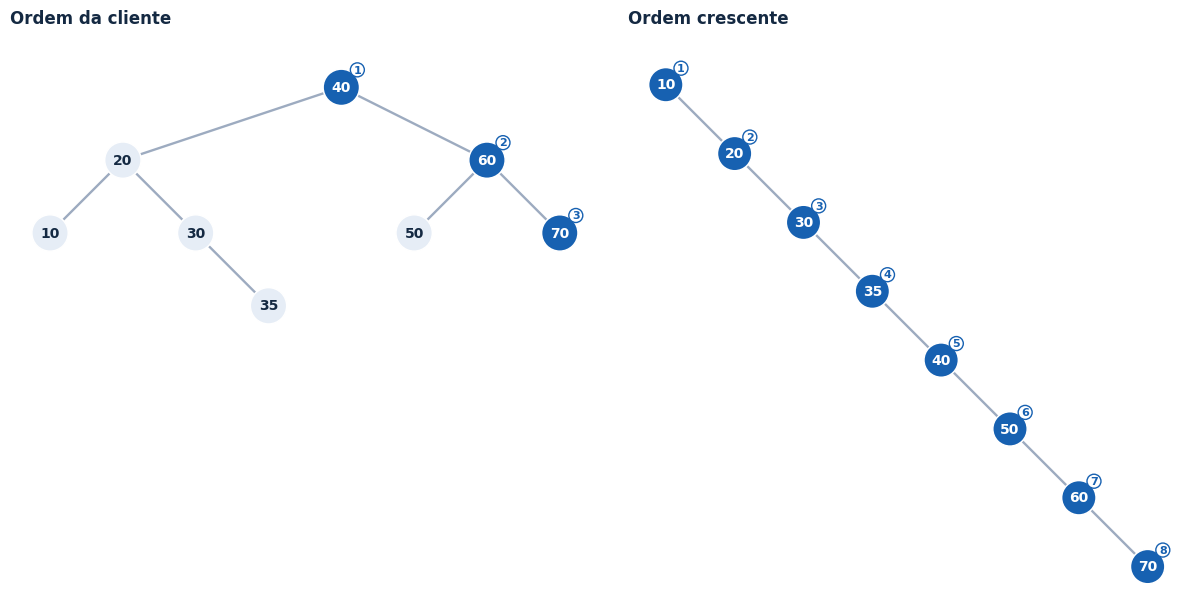

Inventários iguais nas duas árvores? True
CONFERIDO — ordem de inserção e custo da busca


In [29]:
def lab_experimento_altura():
    fig, eixos = painel(altura=6)
    inventarios = []
    for nome, dados, eixo in zip(
        ("Ordem da cliente", "Ordem crescente"),
        (ORDEM_CADASTRO, sorted(ORDEM_CADASTRO)),
        eixos,
    ):
        cadastro = lab_montar(dados)
        encontrado, caminho = lab_buscar(cadastro, 70)
        inventarios.append(lab_inventario(cadastro))
        desenhar(cadastro, nome, ax=eixo, visitados=caminho, numerar=True)
        print(f"\n{nome}")
        print("Altura em arestas:", altura(cadastro))
        print("Caminho até 70:", caminho)
        print("Nós consultados:", len(caminho))
        assert eh_abb(cadastro), "As duas construções devem preservar a ABB."
        assert encontrado is not None and encontrado.chave == 70, "A consulta falhou."
        assert len(caminho) <= altura(cadastro) + 1, "O caminho não deveria exceder h + 1 nós."
    plt.show()
    print("Inventários iguais nas duas árvores?", inventarios[0] == inventarios[1])
    assert inventarios[0] == inventarios[1], "Mudar a ordem de inserção não deve mudar as etiquetas."

lab_conferir("ordem de inserção e custo da busca", lab_experimento_altura)

### Respostas · Etapa 7

**P10 — Previsão da comparação:** A árvore construída com a ordem da cliente terá altura menor por ser mais equilibrada, enquanto a árvore em ordem crescente se tornará degenerada (formato de lista encadeada).

| Medida | Ordem da cliente | Ordem crescente |
|---|---|---|
| Altura em arestas | 3 | 7 |
| Caminho até 70 | [40, 60, 70] | [10, 20, 30, 35, 40, 50, 60, 70] |
| Nós consultados | 3 | 8 |

**Interpretação:** Ambas as árvores são ABBs válidas. Os inventários são iguais porque contêm as mesmas chaves e o percurso em ordem sempre gera a saída ordenada. Os caminhos, porém, são diferentes porque a ordem de inserção determinou topologias distintas. A afirmação "uma ABB sempre busca em O(logn)" não se sustenta: na árvore degenerada, o custo da busca foi linear, O(n), mostrando que o desempenho depende diretamente da altura h.

**Complexidade e compromisso do projeto:**

| Operação | Pior caso com altura h | Se h cresce como log n | Se a árvore vira uma cadeia |
|---|---|---|---|
| Buscar, inserir ou remover uma chave | $O(h)$ | $O(\log n)$ | $O(n)$ |
| Gerar o inventário completo | $O(n)$ | $O(n)$ | $O(n)$ |

**P11 — Resposta à cliente:** O sistema localiza um equipamento comparando a etiqueta procurada com a do nó atual e seguindo um único ramo por vez. Quando a árvore está equilibrada, cada comparação descarta uma boa parte dos candidatos. O inventário ordenado é gerado percorrendo toda a árvore da esquerda para a direita. Porém, se as etiquetas forem inseridas em ordem crescente (ou decrescente), a árvore vira uma lista e a busca perde eficiência, por isso é importante manter a estrutura balanceada.

## Referências

- CORMEN, T. H. et al. *Algoritmos: teoria e prática*. 4. ed. GEN LTC, 2024.
- SZWARCFITER, J. L.; MARKENZON, L. *Estruturas de Dados e Seus Algoritmos*. 3. ed. LTC, 2010.
- ZIVIANI, N. *Projeto de Algoritmos: com implementações em Java e C++*. Cengage Learning Brasil, 2012.
- TENENBAUM, A. M.; LANGSAM, Y.; AUGENSTEIN, M. J. *Estruturas de Dados Usando C*. Makron Books, 1995. Seções 5.1 e 5.2 para a revisão de árvores binárias e percursos.